# Local transcript recovery: saved text diagnostics

All inputs are TEXT fixtures, including ASR-like spellings; no audio is decoded or transcribed in this experiment.

Prompt examples, known user examples, development fixtures and controls are reported separately. They are exposed cases, not an independently sampled test set.

Exact-target agreement compares the returned effective text, including a preserved raw fallback, with the supplied fixture target after token normalization. Text agreement does not mean recovery was accepted; status agreement is reported separately. This is not audio WER, pronunciation quality, semantic correctness, or population accuracy.

An accepted recovery is an inferred interpretation, not proof of the words spoken. Preserve the raw transcript and require confirmation before using an inferred interpretation as a pronunciation reference.

Latency includes this recorded recovery operation only. It excludes microphone capture, ASR, pronunciation assessment, conversation generation, TTS and playback.

This report only reads recorded results. It starts no training, model inference, API call, or audio request.

In [1]:
from pathlib import Path
import hashlib, json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/report_transcript_recovery.py').is_file())
sys.path.insert(0, str(ROOT))
from scripts.report_transcript_recovery import load_results, case_rows, group_summary, failure_rows, plot_results
SOURCE = ROOT / 'data/generated/transcript-recovery-v1/probe-02/results.json'
result = load_results(SOURCE)
source_sha256 = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
print('Recorded TEXT fixtures:', len(result['cases']))
print('Model:', result.get('model_id'), '| Version:', result.get('version'))
print('Source SHA256:', source_sha256)
print('No audio, model inference, API calls, or training run in this notebook.')

Recorded TEXT fixtures: 12
Model: qwen-base | Version: guarded_intent_recovery_v1
Source SHA256: 3453586eac22a23582bee496e32bc3650518336c2bd36d266b269e39a0a513e2
No audio, model inference, API calls, or training run in this notebook.


In [2]:
print('Exposed fixture groups — counts only, not population accuracy')
display(pd.DataFrame(group_summary(result)))
print('Prompt examples and known user examples are not independent test cases.')

Exposed fixture groups — counts only, not population accuracy


,group,cases,selected_outputs,target_matches,target_mismatches,not_target_scored,expected_status_matches
0,prompt_example,3,2,2,0,1,3
1,development,4,4,4,0,0,4
2,known_user_example,2,0,0,2,0,0
3,control,3,1,2,0,1,2


Prompt examples and known user examples are not independent test cases.


In [3]:
rows = pd.DataFrame(case_rows(result))
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(rows)
print('Raw text is preserved. An inferred recovery is not a verified spoken-word reference.')

,id,group,raw_transcript,recovery_output,expected_text,status,expected_status,reason,target_match,status_match,seconds
0,today_prompt_example,prompt_example,i have a meeting to day,I have a meeting today.,I have a meeting today.,accepted,accepted,None,True,True,9.422
1,today_variant,development,i stayed at home to day,I stayed at home today.,I stayed at home today.,accepted,accepted,None,True,True,1.032
2,software_variant,development,My brother is a soft ware developer,My brother is a software developer.,My brother is a software developer.,unchanged,unchanged,None,True,True,1.296
3,favorite_variant,development,My fravorit food is pizza,My favorite food is pizza.,My favorite food is pizza.,accepted,accepted,None,True,True,1.250
4,engineer_variant,development,I work as a sockway engineer,I work as a software engineer.,I work as a software engineer.,accepted,accepted,None,True,True,1.407
5,journey_user_example,known_user_example,It was the divicote true getesir,It was the divicote true getesir,It was difficult to get there.,ambiguous,accepted,unclear_intent,False,False,0.953
6,occupation_user_example,known_user_example,Curly am ma a sockway engineer,Curly am ma a sockway engineer,"Currently, I am a software engineer.",ambiguous,accepted,unsupported_spelling_change,False,False,1.265
7,negation_number_control,control,I do not want two coffees,I do not want two coffees.,I do not want two coffees.,unchanged,unchanged,None,True,True,1.219
8,grammar_control,control,I usually wakes up at seven am,I usually wakes up at seven am,I usually wakes up at seven am.,unavailable,unchanged,grammar_change,True,False,1.766
9,nonsense_prompt_example,prompt_example,Banana software yesterday purple,Banana software yesterday purple,None,ambiguous,ambiguous,unclear_intent,None,True,1.734


Raw text is preserved. An inferred recovery is not a verified spoken-word reference.


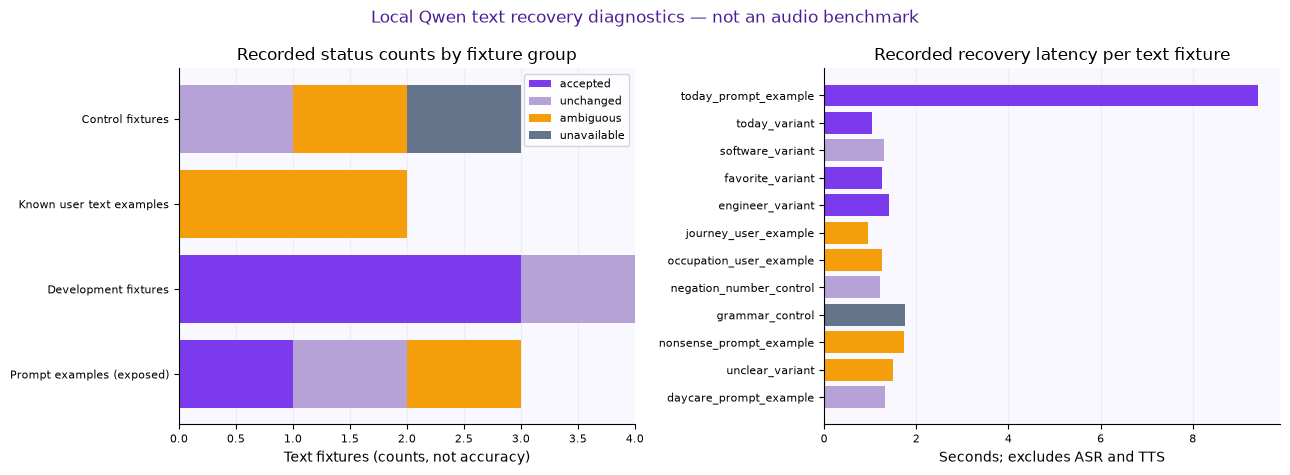

These latencies exclude ASR, conversation, pronunciation assessment, and TTS.


In [4]:
figure = plot_results(result)
display(figure)
plt.close(figure)
print('These latencies exclude ASR, conversation, pronunciation assessment, and TTS.')

In [5]:
failures = failure_rows(result)
print('Fixture target or status mismatches:', len(failures))
display(pd.DataFrame(failures))
for case in result['cases']:
    print(json.dumps({'id': case['id'], 'group': case.get('group'), 'history': case.get('history', []), 'result': case['result'], 'raw_model_output': case.get('raw_model_output'), 'generation': case.get('generation')}, ensure_ascii=False, indent=2))
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == source_sha256
print('Results file remained unchanged. No accuracy or WER claim is made.')

Fixture target or status mismatches: 3


,id,group,raw_transcript,recovery_output,expected_text,status,expected_status,reason,target_match,status_match,seconds
0,journey_user_example,known_user_example,It was the divicote true getesir,It was the divicote true getesir,It was difficult to get there.,ambiguous,accepted,unclear_intent,False,False,0.953
1,occupation_user_example,known_user_example,Curly am ma a sockway engineer,Curly am ma a sockway engineer,"Currently, I am a software engineer.",ambiguous,accepted,unsupported_spelling_change,False,False,1.265
2,grammar_control,control,I usually wakes up at seven am,I usually wakes up at seven am,I usually wakes up at seven am.,unavailable,unchanged,grammar_change,True,False,1.766


{
  "id": "today_prompt_example",
  "group": "prompt_example",
  "history": [],
  "result": {
    "version": "guarded_intent_recovery_v1",
    "original": "i have a meeting to day",
    "text": "I have a meeting today.",
    "status": "accepted",
    "changed": true,
    "requires_confirmation": true,
    "source": "qwen_inferred",
    "reason": null,
    "reference_confirmed": false,
    "lexical_preservation": false,
    "latency_sec": 9.422
  },
  "raw_model_output": "{\"status\": \"recovered\", \"text\": \"I have a meeting today.\"}",
  "generation": {
    "finish_reason": "stop",
    "usage": {
      "prompt_tokens": 561,
      "completion_tokens": 19
    },
    "context_messages_dropped": 0,
    "generation_profile": null,
    "sampling": {
      "do_sample": false
    },
    "latency_sec": 1.609,
    "generation_latency_sec": 1.609,
    "model_load_sec": 4.907,
    "qwen_runtime": {
      "requested": "auto",
      "device": "cuda:0",
      "dtype": "bfloat16",
      "attention"